# 03 · A first reduced model of TS1

Notebook 02 measured what a reduced model of toric spine TS1 must
reproduce. This notebook **builds one** and checks it against the
reference model (the 3D FEM of TS1).

**The idea (tree realization).** For a passive spine, everything a
simulator needs is how its **ports** (25 synapses plus the neck) are
related electrically. Notebook 02 showed that the resistances between
TS1's ports are close to those of a **tree**, despite the holes. So we:

1. fit a **tree of resistors** to the FEM port-to-port resistances. Each
   port is a leaf, and internal branch points carry no membrane;
2. give each tree node a share of the spine's **membrane**;
3. compare the result with the FEM at DC, 100 Hz and 1 kHz;
4. **shrink** the tree and see how accuracy falls with model size.

The reduced model here is evaluated with cabaret's own solver. Exporting
it to jaxley and fine-tuning it with gradients is the next step (plan 006).

**Placeholders** are as in notebook 02: 0.05 µm² per synapse patch. There
is no parent: the spine is modelled on its own, with the neck as a port.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

import cabaret as cb
from cabaret import graft, ports, reduce, toric, viz

pv.set_jupyter_backend("static")

SCALE = 0.005  # µm per pixel
MEMBRANE = cb.Passive(
    r_L=100.0, c_m=1.0, g_pas=2.63e-4
)  # high-conductance, as in notebook 02
FREQS = [0.0, 100.0, 1000.0]  # Hz, roughly the frequency content of synaptic signals

## 1. TS1 reference model

`toric.load_toric_spine` repeats notebook 02's setup in one call: mesh and FEM
model, the neck port (where the separately traced TS1 meets the
whole-cell mesh, tied into one electrode), and the 25 active zones (AZs)
snapped onto the membrane. The ports are ordered **neck first, then AZ 0
to AZ 24**.

In [2]:
parts = graft.load_parts("../data/neuromesh/parts", scale=SCALE)
ts1 = toric.load_toric_spine("TS1", "../data", parts, scale=SCALE)
neck_port = ts1.attachment_ports[0]
port_patches = [neck_port, *ts1.sites.patches]  # port 0 = neck, port k = AZ k−1
port_names = ["neck"] + [f"AZ {i}" for i in range(len(ts1.sites))]

z_fem = cb.port_impedance(ts1.network, MEMBRANE, port_patches, FREQS)  # (3, 26, 26) Ω
zc_fem = ports.clamp_port(
    z_fem[0].real, 0
)  # neck clamped: the spine's internal structure
lobe = ports.electrical_groups(zc_fem, n_groups=2)  # the two lobes found in notebook 02
print(f"{len(ts1.sites)} AZs, {ts1.network.n_nodes} FEM nodes")

Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 elements to C_CONTIGUOUS.


25 AZs, 34129 FEM nodes


## 2. Fit a tree to the port resistances

**Resistance distance** between two ports is the resistance between them
with the membrane removed (notebook 02, section 8). We fit a tree to these
distances in two steps:
- **topology** from *neighbor-joining*, the standard algorithm for
  building phylogenetic trees from distances;
- **branch resistances** refitted by least squares over all port pairs,
  constrained to be non-negative (a negative resistor is unphysical).

**Fit error** is how far the tree's port-to-port resistances are from the
FEM's, relative and over all pairs. Notebook 02's loopiness analysis
predicted about 1% typically.

**The drawing** puts the neck (black) at the centre. Every node's distance
from the centre is its resistance from the neck, in MΩ, so electrically
remote synapses sit far out. Synapses are coloured by lobe. Small grey dots
are internal branch points, where branches split. Branches never cross:
each subtree gets its own angular sector.

tree: 50 nodes (26 ports + 24 branch points)
port-to-port resistance fit error: 1.35%


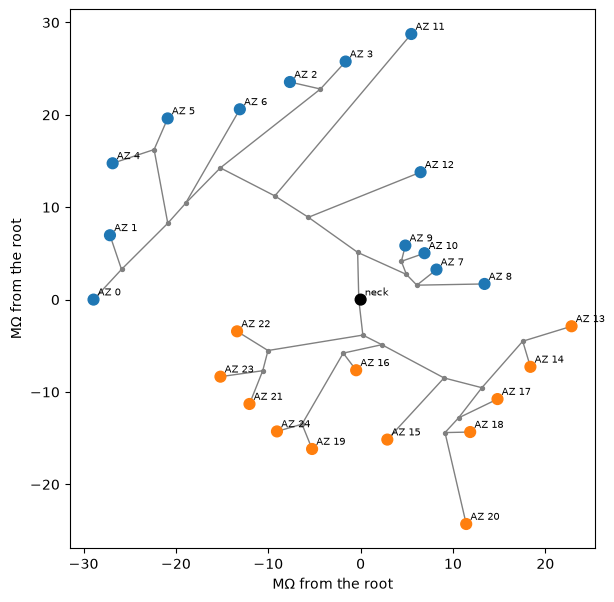

In [3]:
metric = ports.ResistanceMetric(ts1.network, MEMBRANE, ground=neck_port)
d_fem = metric.distances(ts1.sites.patches)  # (26, 26) Ω, neck = port 0
tree = reduce.fit_tree(d_fem)
n_internal = tree.n_nodes - len(tree.port_node)
print(
    f"tree: {tree.n_nodes} nodes ({len(tree.port_node)} ports + {n_internal} branch points)"
)
print(f"port-to-port resistance fit error: {100 * tree.fit_error:.2f}%")

viz.plot_port_tree(tree, port_names, colors=[-1, *lobe])
plt.show()

**Reading:** right at the neck the tree splits into two subtrees, one per
lobe, as notebook 02 predicted. Within each lobe, synapses hang off
branches of different lengths. That is the 4× spread in spine-local
resistance, now visible as distance from the centre.

## 3. Put the membrane on the tree

The tree fixes the *resistances*. Each node also needs *membrane* (it sets
capacitance and leak, and later channel densities). Each patch of FEM
membrane goes to the port it **behaves most like**: with the neck held at
rest, inject current at each synapse in turn and record every membrane
vertex's voltages. That gives each vertex a "fingerprint". A vertex goes
to the port with the most similar fingerprint, or to the neck if it barely
responds at all. Internal branch points get no membrane.

The view colours the membrane by the port it was given to (0 = neck,
k = AZ k−1). −1 marks surface with no membrane: the neck region tied into
the electrode. Total membrane is conserved exactly.

membrane: neck 8.8 µm², synapse nodes 0.17–6.07 µm² (total 71.3 µm²)


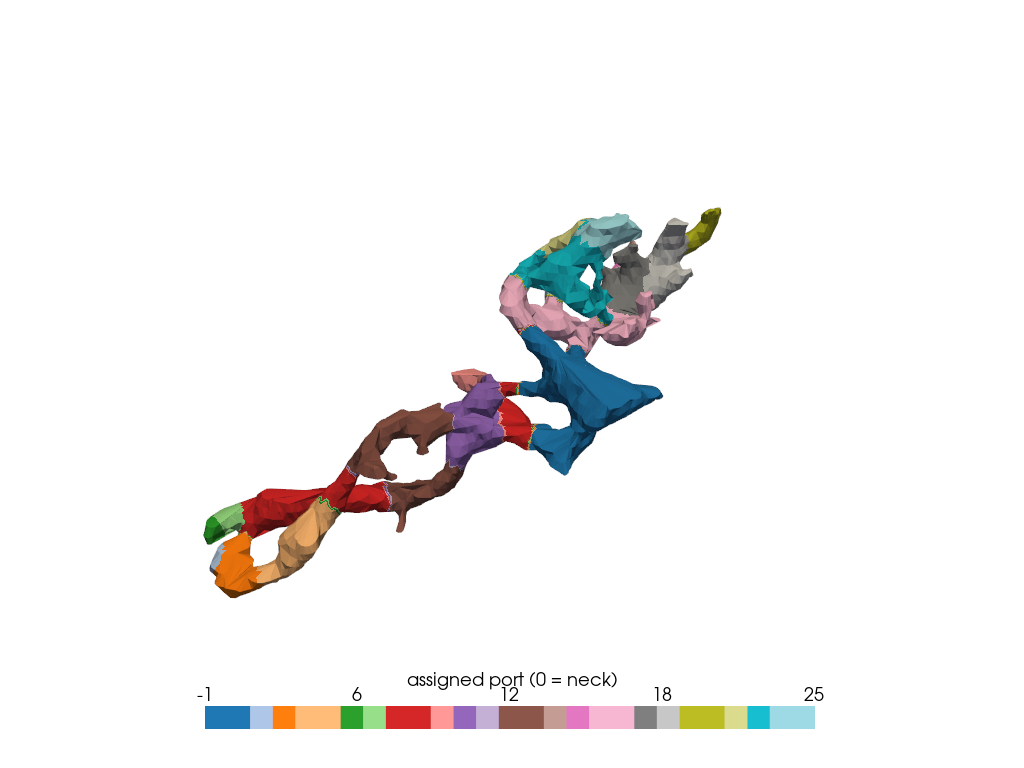

In [4]:
owner = reduce.assign_membrane(
    ts1.network, MEMBRANE, ts1.sites.patches, ground=neck_port
)
has_membrane = owner >= 0
port_area = np.bincount(
    owner[has_membrane],
    weights=ts1.network.area[has_membrane],
    minlength=len(port_patches),
)  # µm² per port, neck first
print(
    f"membrane: neck {port_area[0]:.1f} µm², synapse nodes "
    f"{port_area[1:].min():.2f}–{port_area[1:].max():.2f} µm² "
    f"(total {port_area.sum():.1f} µm²)"
)
n_mesh = len(ts1.tets.points)
pl = viz.plot_surface(
    ts1.tets,
    owner[:n_mesh].astype(float),
    name="assigned port (0 = neck)",
    cmap="tab20",
    categories=True,
)
pl.show()

## 4. The reduced model against the FEM

The tree and its membrane define a small network: one compartment per tree
node (50 here, against about 34,000 FEM nodes). Its port impedance matrix
is compared with the FEM's in two forms (notebook 02, section 4):

- **isolated spine** (neck floating). Dominated by the total membrane, so
  it is easy to match. A sanity check;
- **neck clamped**: the spine's internal structure, how synapses see each
  other. **This is the real test.**

The scatter plot compares every entry of the clamped matrix (each dot is
one pair of synapses) at DC. Dots on the diagonal line are reproduced
exactly. The bar plot shows each synapse's own spine-local input
resistance error.

     0 Hz: isolated error 0.01%, neck-clamped error 2.83%
   100 Hz: isolated error 0.01%, neck-clamped error 2.83%
  1000 Hz: isolated error 0.11%, neck-clamped error 2.83%


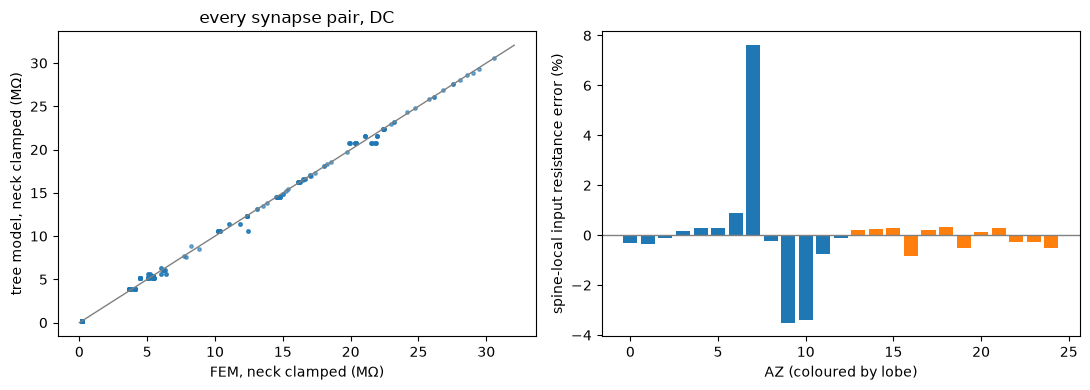

spine-local input resistance error: median 0.29%, max 7.6%


In [5]:
def node_areas(t: reduce.PortTree) -> np.ndarray:
    """Membrane per tree node: each port's assigned membrane on its node."""
    area = np.zeros(t.n_nodes)
    np.add.at(area, t.port_node, port_area)
    return area


def reduced_port_matrix(t: reduce.PortTree) -> np.ndarray:
    """Port impedance matrix of a tree model at FREQS, ports in FEM order."""
    g = reduce.tree_to_graph(t, MEMBRANE, node_areas(t))
    return cb.port_impedance(
        g, MEMBRANE, [cb.point_port(g, int(n)) for n in t.port_node], FREQS
    )


z_tree = reduced_port_matrix(tree)
for k, f in enumerate(FREQS):
    e_iso = reduce.port_matrix_error(z_tree[k], z_fem[k])
    e_clamp = reduce.port_matrix_error(
        ports.clamp_port(z_tree[k], 0), ports.clamp_port(z_fem[k], 0)
    )
    print(
        f"{f:>6g} Hz: isolated error {100 * e_iso:.2f}%, neck-clamped error {100 * e_clamp:.2f}%"
    )

zc_tree = ports.clamp_port(z_tree[0].real, 0)
local_err = 100 * (np.diag(zc_tree) / np.diag(zc_fem) - 1)  # % per synapse
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].scatter(zc_fem.ravel() / 1e6, zc_tree.ravel() / 1e6, s=6, alpha=0.6)
lim = [0, zc_fem.max() / 1e6 * 1.05]
axs[0].plot(lim, lim, color="gray", lw=1)
axs[0].set_xlabel("FEM, neck clamped (MΩ)")
axs[0].set_ylabel("tree model, neck clamped (MΩ)")
axs[0].set_title("every synapse pair, DC")
axs[1].bar(range(len(local_err)), local_err, color=[f"C{int(x)}" for x in lobe])
axs[1].axhline(0, color="gray", lw=1)
axs[1].set_xlabel("AZ (coloured by lobe)")
axs[1].set_ylabel("spine-local input resistance error (%)")
fig.tight_layout()
plt.show()
print(
    f"spine-local input resistance error: median {np.median(np.abs(local_err)):.2f}%, "
    f"max {np.max(np.abs(local_err)):.1f}%"
)

**Reading:** a 50-compartment tree reproduces TS1's internal port structure
to about 3%, equally well at 100 Hz and 1 kHz, and most synapses' own
input resistance to well under 1%. The loops of TS1 are absent from this
model, and it barely matters: they act through the resistances they create,
which the tree has absorbed.

**Mesh error.** These are errors against the FEM on a 0.2 µm mesh. That
reference reads spine-local input resistance about 1% low compared with a
0.05 µm mesh (notebook 05). Built from the 0.05 µm FEM instead, the
tree gives nearly the same errors: 3.0% clamped (2.8% here), spine-local
median 0.31% (0.29% here). The roughly 3% error comes from the tree, not
the mesh.

## 5. Smaller models: accuracy against size

The simplest way to shrink the tree is to **merge its shortest branches**:
nodes joined by less than a threshold resistance become one compartment,
whose membrane is the sum. Raising the threshold gives smaller and
smaller models. The left panel shows the clamped error against the number
of compartments.

The right panel shows the **lower bounds** from notebook 02 for comparison,
with *m* = number of compartments that carry synapses:
- **rank bound**: the best any model can do if every synapse sits on one of
  m compartments;
- **diagonal + low rank**: the same, but each synapse also gets its own
  small series resistor (its patch's spreading resistance). Reduced models
  can have this cheaply, so it is the fairer floor.

The two panels count differently: the tree counts every node, including
one leaf per synapse and the branch points.

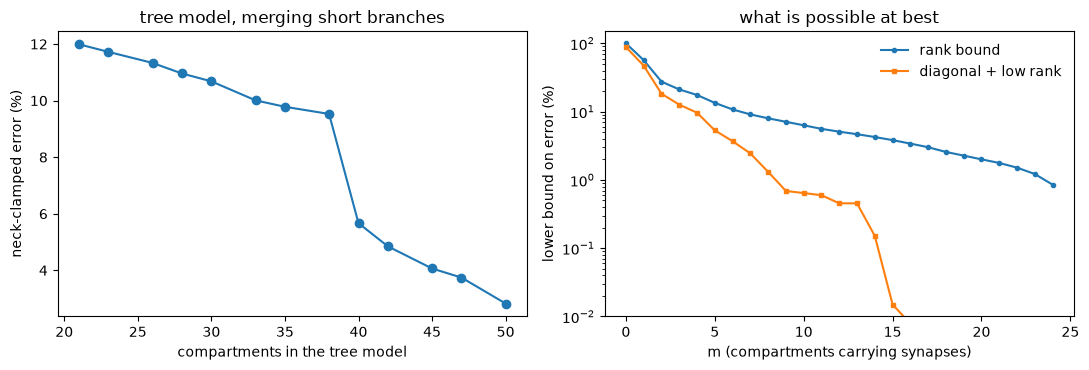

diagonal + low-rank bound: m=2: 18.3%, m=4: 9.6%, m=8: 1.3%, m=12: 0.5%


In [6]:
positive = tree.resistance[tree.resistance > 0]
sizes, errors = [tree.n_nodes], [reduce.port_matrix_error(zc_tree, zc_fem)]
for q in np.linspace(0.05, 0.6, 12):
    small = reduce.contract_tree(tree, np.quantile(positive, q))
    z_small = ports.clamp_port(reduced_port_matrix(small)[0].real, 0)
    sizes.append(small.n_nodes)
    errors.append(reduce.port_matrix_error(z_small, zc_fem))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(sizes, 100 * np.array(errors), "o-")
axs[0].set_xlabel("compartments in the tree model")
axs[0].set_ylabel("neck-clamped error (%)")
axs[0].set_title("tree model, merging short branches")
m = np.arange(len(zc_fem) + 1)
axs[1].semilogy(
    m[:-1], 100 * ports.rank_bound(zc_fem)[:-1], "o-", ms=3, label="rank bound"
)
axs[1].semilogy(
    m[:-1],
    100 * ports.diag_lowrank_bound(zc_fem)[:-1],
    "s-",
    ms=3,
    label="diagonal + low rank",
)
axs[1].set_xlabel("m (compartments carrying synapses)")
axs[1].set_ylabel("lower bound on error (%)")
axs[1].set_title("what is possible at best")
axs[1].set_ylim(1e-2, 150)  # below 0.01% is numerically zero
axs[1].legend(frameon=False)
fig.tight_layout()
plt.show()
dl = ports.diag_lowrank_bound(zc_fem)
print(
    "diagonal + low-rank bound:",
    ", ".join(f"m={k}: {100 * dl[k]:.1f}%" for k in (2, 4, 8, 12)),
)

**Reading:**
- merging branches is a **crude** way to shrink the model: the error rises
  quickly below about 40 compartments;
- the bounds show **much more is possible**: with a private resistor per
  synapse, about 8 shared compartments could in principle get within about
  1%;
- closing that gap is the job of the next step: choosing which synapses
  share a compartment, then **fitting** resistances and membrane directly to
  the FEM by gradient descent through jaxley (plan 006).

## Summary

- A **loop-free tree** of 50 compartments reproduces TS1's FEM port
  structure to about 3%, from DC to 1 kHz.
- The tree's shape mirrors the **two lobes** found in notebook 02.
- Smaller models are possible in principle (the diagonal + low-rank bound
  says about 8 shared compartments for about 1%), but simple branch merging
  doesn't get there. A fitted reduction should.